<a href="https://colab.research.google.com/github/Lynna5639582/Lynna5639582-DataScience-GenAI-Submissions/blob/main/7_01_Exploratory_Data_Analysis_Salary_Student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1xqQczl0FG-qtNA2_WQYuWePW9oU8irqJ)

# 2.05 Exploratory Data Analysis (EDA)
In this exercise, you will explore a salary dataset (`EDA-DP.csv`) from the Week 7 Seminar Resources on myWBS. Work through the tasks in order. The setup cell below imports the libraries and allows you to upload the dataset.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from google.colab import files
upload = files.upload()

Saving EDA-DP.csv to EDA-DP.csv


**Task 1 — Load the data.** Read `EDA-DP.csv` into a pandas DataFrame and display the first few rows.

In [7]:
import pandas as pd
import numpy as np

In [8]:
testdf = pd.read_csv('EDA-DP.csv')
testdf.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2024,SE,FT,AI Engineer,202730,USD,202730,US,0,US,M
1,2024,SE,FT,AI Engineer,92118,USD,92118,US,0,US,M
2,2024,SE,FT,Data Engineer,130500,USD,130500,US,0,US,M
3,2024,SE,FT,Data Engineer,96000,USD,96000,US,0,US,M
4,2024,SE,FT,Machine Learning Engineer,190000,USD,190000,US,0,US,M


**Task 2 — Dataset size.** Find the number of rows and columns in the dataset.

In [11]:
testdf.shape

(16534, 11)

**Task 3 — Dataset structure.** Inspect the column names, data types, and number of non-missing values.

In [12]:
testdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16534 entries, 0 to 16533
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           16534 non-null  int64 
 1   experience_level    16534 non-null  object
 2   employment_type     16534 non-null  object
 3   job_title           16534 non-null  object
 4   salary              16534 non-null  int64 
 5   salary_currency     16534 non-null  object
 6   salary_in_usd       16534 non-null  int64 
 7   employee_residence  16534 non-null  object
 8   remote_ratio        16534 non-null  int64 
 9   company_location    16534 non-null  object
 10  company_size        16534 non-null  object
dtypes: int64(4), object(7)
memory usage: 1.4+ MB


**Task 4 — Missing data.** Check how many missing values there are in each column.

In [13]:
testdf.isnull().sum()

,0
work_year,0
experience_level,0
employment_type,0
job_title,0
salary,0
salary_currency,0
salary_in_usd,0
employee_residence,0
remote_ratio,0
company_location,0


**Task 5 — Missing-data percentages.** Calculate the percentage of missing values for each column. Think about how you would handle missing data if you found any.

In [14]:
(testdf.isnull().sum() / len(testdf)) * 100

,0
work_year,0.0
experience_level,0.0
employment_type,0.0
job_title,0.0
salary,0.0
salary_currency,0.0
salary_in_usd,0.0
employee_residence,0.0
remote_ratio,0.0
company_location,0.0


**Task 6 — Duplicates.** Find how many rows are exact duplicates and how many are not. Would identical records necessarily be errors in this dataset?

In [16]:
num_duplicates = testdf.duplicated().sum()
num_unique = (~testdf.duplicated()).sum()

print(f"Number of exact duplicate rows: {num_duplicates}")
print(f"Number of unique rows: {num_unique}")

Number of exact duplicate rows: 6421
Number of unique rows: 10113


**Task 7 — Summary statistics.** Produce descriptive statistics for the numerical columns. What do the distributions tell you? Note that `salary` may use different currencies, whereas `salary_in_usd` is comparable across records.

In [17]:
testdf.describe()

,work_year,salary,salary_in_usd,remote_ratio
count,16534.000000,1.653400e+04,16534.000000,16534.000000
mean,2023.226866,1.637270e+05,149686.777973,32.003750
std,0.713558,3.402057e+05,68505.293156,46.245158
min,2020.000000,1.400000e+04,15000.000000,0.000000
25%,2023.000000,1.017630e+05,101125.000000,0.000000
50%,2023.000000,1.422000e+05,141300.000000,0.000000
75%,2024.000000,1.872000e+05,185900.000000,100.000000
max,2024.000000,3.040000e+07,800000.000000,100.000000


### Visualising the Data

**Task 8 — Bar chart.** Create a bar chart comparing the **average salary in USD** across experience levels (`EN`, `MI`, `SE`, `EX`). Add clear axis labels and a title. Which group has the highest average?

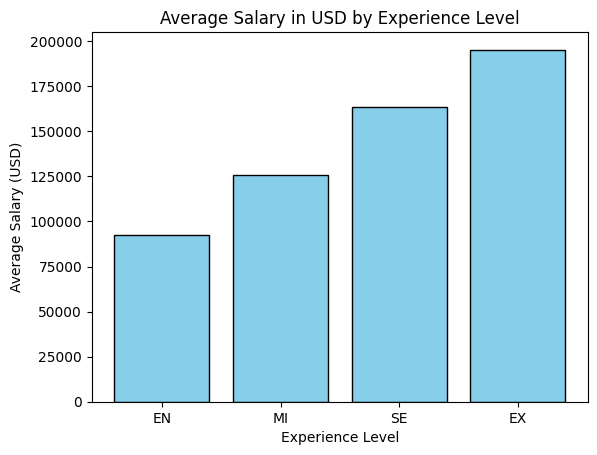

In [19]:
# Group by experience level and calculate the average salary in USD
avg_salary = testdf.groupby('experience_level')['salary_in_usd'].mean().reindex(['EN', 'MI', 'SE', 'EX'])

# Create the bar chart
plt.bar(avg_salary.index, avg_salary.values, color='skyblue', edgecolor='black')
plt.xlabel('Experience Level')
plt.ylabel('Average Salary (USD)')
plt.title('Average Salary in USD by Experience Level')
plt.show()

**Task 9 — Scatter plot.** Make a scatter plot of `work_year` against `salary_in_usd`. Label the axes. What patterns do you notice? Are any points difficult to distinguish because they overlap?

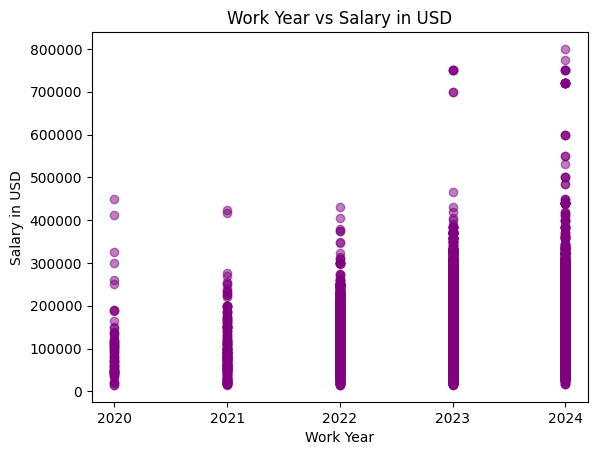

In [20]:
plt.scatter(testdf['work_year'], testdf['salary_in_usd'], alpha=0.5, color='purple')
plt.xlabel('Work Year')
plt.ylabel('Salary in USD')
plt.title('Work Year vs Salary in USD')
plt.xticks([2020, 2021, 2022, 2023, 2024])
plt.show()

**Task 10 — Distribution.** Plot the distribution of `salary_in_usd`. Does it look approximately normal, skewed, or something else? Are there extreme values?

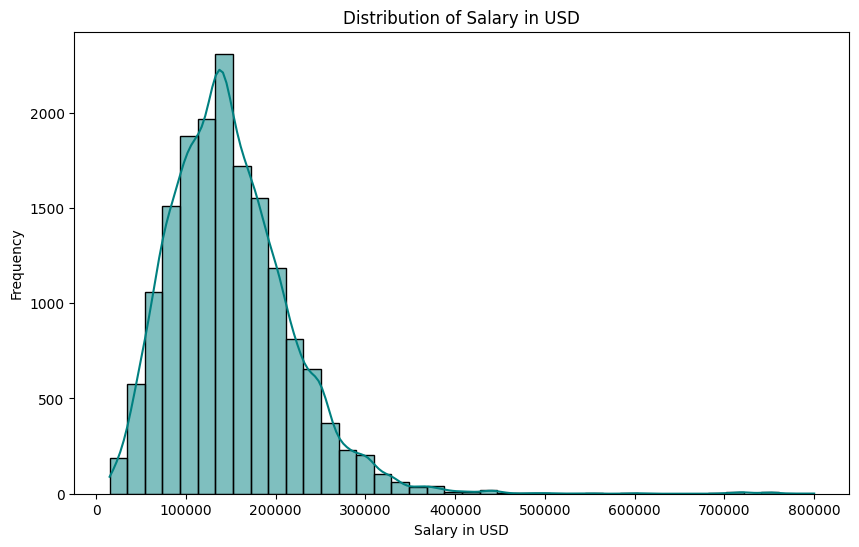

In [22]:
# Plot the distribution of salary_in_usd
plt.figure(figsize=(10, 6))
sns.histplot(testdf['salary_in_usd'], kde=True, color='teal', bins=40)
plt.xlabel('Salary in USD')
plt.ylabel('Frequency')
plt.title('Distribution of Salary in USD')
plt.show()

**Task 11 — Pairwise relationships.** Visualize pairwise relationships among `salary_in_usd`, `work_year`, and `remote_ratio`, including distributions of the individual variables.

Try to compare the variables in one combined visualization. What relationships or patterns do you notice?

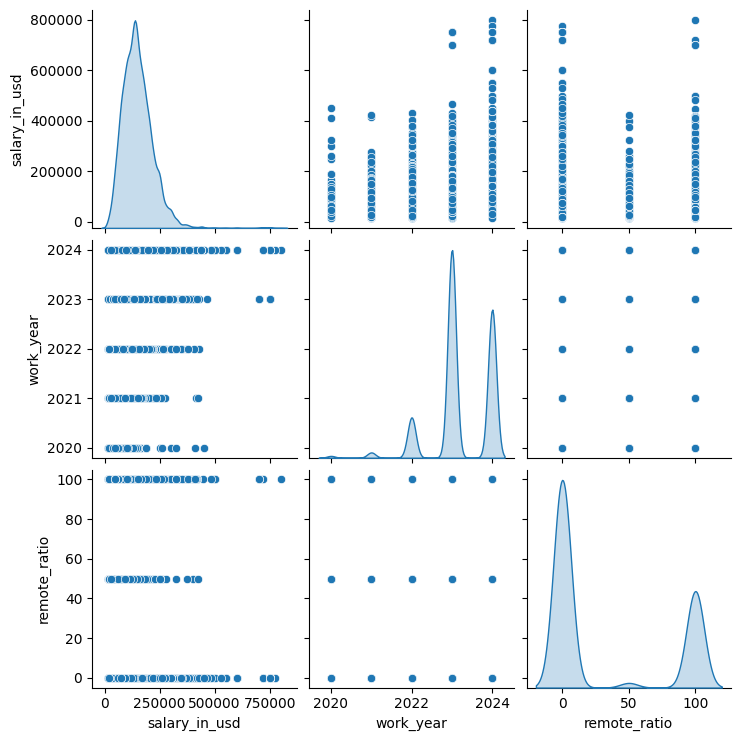

In [24]:
# Plot pairwise relationships between salary_in_usd, work_year, and remote_ratio
sns.pairplot(testdf[['salary_in_usd', 'work_year', 'remote_ratio']], diag_kind='kde')
plt.show()

**Task 12 — Remove a column.** Remove the original-currency `salary` column while retaining `salary_in_usd`, then inspect the updated DataFrame. Why might you choose to keep one salary column rather than both?

In [26]:
# Drop the redundant 'salary' column and inspect the updated DataFrame
testdf_cleaned = testdf.drop(columns=['salary'])
print(testdf_cleaned.head())
print(f"\nRemaining columns: {list(testdf_cleaned.columns)}")

   work_year experience_level employment_type                  job_title  \
0       2024               SE              FT                AI Engineer   
1       2024               SE              FT                AI Engineer   
2       2024               SE              FT              Data Engineer   
3       2024               SE              FT              Data Engineer   
4       2024               SE              FT  Machine Learning Engineer   

  salary_currency  salary_in_usd employee_residence  remote_ratio  \
0             USD         202730                 US             0   
1             USD          92118                 US             0   
2             USD         130500                 US             0   
3             USD          96000                 US             0   
4             USD         190000                 US             0   

  company_location company_size  
0               US            M  
1               US            M  
2               US        

**Reflection.** What have you learned about the salary dataset? Which additional checks or visualizations would be useful before building a machine learning model?

Well done!

In [ ]:
Reflection: Based on the dataset above, I believe having a decision tree would be helpful, especially when handling categorical data. Whilst they are great for visualising and simplicity of the dataset, GBDT would be even better as it builds an ensemble of trees, where each new tree corrects the errors in the previous tree, leading to a high predictive accuracy.